# 01 - Exploratory Data Analysis (EDA)

**Project:** CardioLens - Early Heart Disease Risk Prediction using Explainable Machine Learning

This notebook explores the Kaggle Heart Disease dataset **before** any modelling. It answers four questions:

1. Is the data clean? (duplicates, invalid codes, missing values)
2. What does the target look like? (label direction and class balance)
3. How are the features distributed, and how do they differ between patients with and without heart disease?
4. Which features move together with the disease label?

The cleaning decisions made here are the same ones applied in `src/data_audit.py` and `src/preprocess.py`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
RAW = Path("../data/raw/heart.csv")
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(RAW)
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


## 1. Data quality

In [2]:
print("Missing values per column:")
print(raw.isna().sum().to_string())
print()
print("Data types:")
print(raw.dtypes.to_string())

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0

Data types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64


In [3]:
n_dup = raw.duplicated().sum()
df = raw.drop_duplicates().reset_index(drop=True)
print(f"Raw rows: {len(raw)}")
print(f"Duplicate rows: {n_dup} ({n_dup / len(raw):.1%})")
print(f"Unique patients kept: {len(df)}")

Raw rows: 1025
Duplicate rows: 723 (70.5%)
Unique patients kept: 302


**Finding:** about 70% of the raw file is repeated rows. If these were left in, identical patients would land in both the training and test sets, which inflates every score. Duplicates are therefore removed **before** the train/test split.

In [4]:
print("Rows with ca = 4 :", (df["ca"] == 4).sum(), "(valid range is 0-3)")
print("Rows with thal = 0:", (df["thal"] == 0).sum(), "(valid codes are 1-3)")
print()
print(df[["age", "trestbps", "chol", "thalach", "oldpeak"]].describe().round(2).to_string())

Rows with ca = 4 : 4 (valid range is 0-3)
Rows with thal = 0: 2 (valid codes are 1-3)

          age  trestbps    chol  thalach  oldpeak
count  302.00    302.00  302.00   302.00   302.00
mean    54.42    131.60  246.50   149.57     1.04
std      9.05     17.56   51.75    22.90     1.16
min     29.00     94.00  126.00    71.00     0.00
25%     48.00    120.00  211.00   133.25     0.00
50%     55.50    130.00  240.50   152.50     0.80
75%     61.00    140.00  274.75   166.00     1.60
max     77.00    200.00  564.00   202.00     6.20


**Finding:** `ca = 4` and `thal = 0` are not valid codes in this dataset. They are treated as missing and imputed inside the modelling pipeline using values learned from the training split only.

## 2. Target: label direction and class balance

In [5]:
check = df.groupby("target").agg(
    mean_max_heart_rate=("thalach", "mean"),
    mean_st_depression=("oldpeak", "mean"),
    exercise_angina_rate=("exang", "mean"),
    share_with_zero_vessels=("ca", lambda s: (s == 0).mean()),
).round(3)
check

,mean_max_heart_rate,mean_st_depression,exercise_angina_rate,share_with_zero_vessels
target,,,,
0,139.101,1.586,0.551,0.326
1,158.378,0.587,0.140,0.793


**Finding:** patients with `target = 1` have a higher maximum heart rate, lower ST depression, less exercise angina and more often zero blocked vessels. That is the clinical pattern of **healthy** patients, so in this file `target = 1` means *no* disease. The project therefore uses `disease = 1 - target` everywhere.

disease
Disease absent     164
Disease present    138

disease
Disease absent     0.543
Disease present    0.457


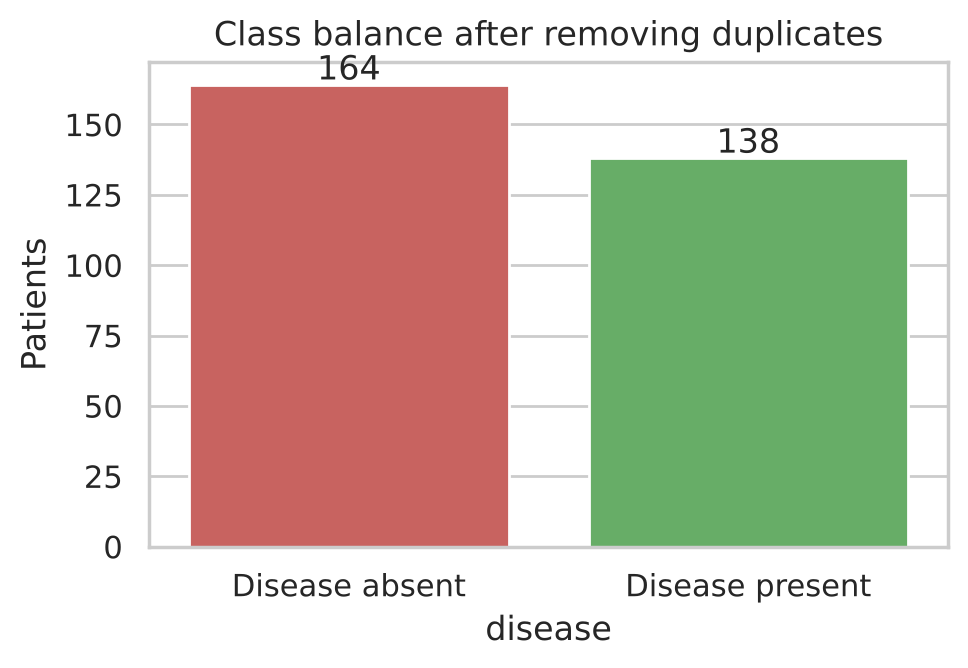

In [6]:
df["disease"] = 1 - df["target"]
balance = df["disease"].value_counts().rename({1: "Disease present", 0: "Disease absent"})
print(balance.to_string())
print()
print((balance / len(df)).round(3).to_string())

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=balance.index, y=balance.values, hue=balance.index, palette=["#D9534F", "#5CB85C"], legend=False, ax=ax)
ax.set_ylabel("Patients")
ax.set_title("Class balance after removing duplicates")
for i, v in enumerate(balance.values):
    ax.text(i, v + 2, str(v), ha="center")
plt.tight_layout()
plt.savefig(FIG / "class_balance.png", dpi=150)
plt.show()

**Finding:** the classes are fairly balanced, so accuracy is not misleading on its own, but the project still prioritises **recall** because a missed patient is the costly error.

## 3. Feature distributions

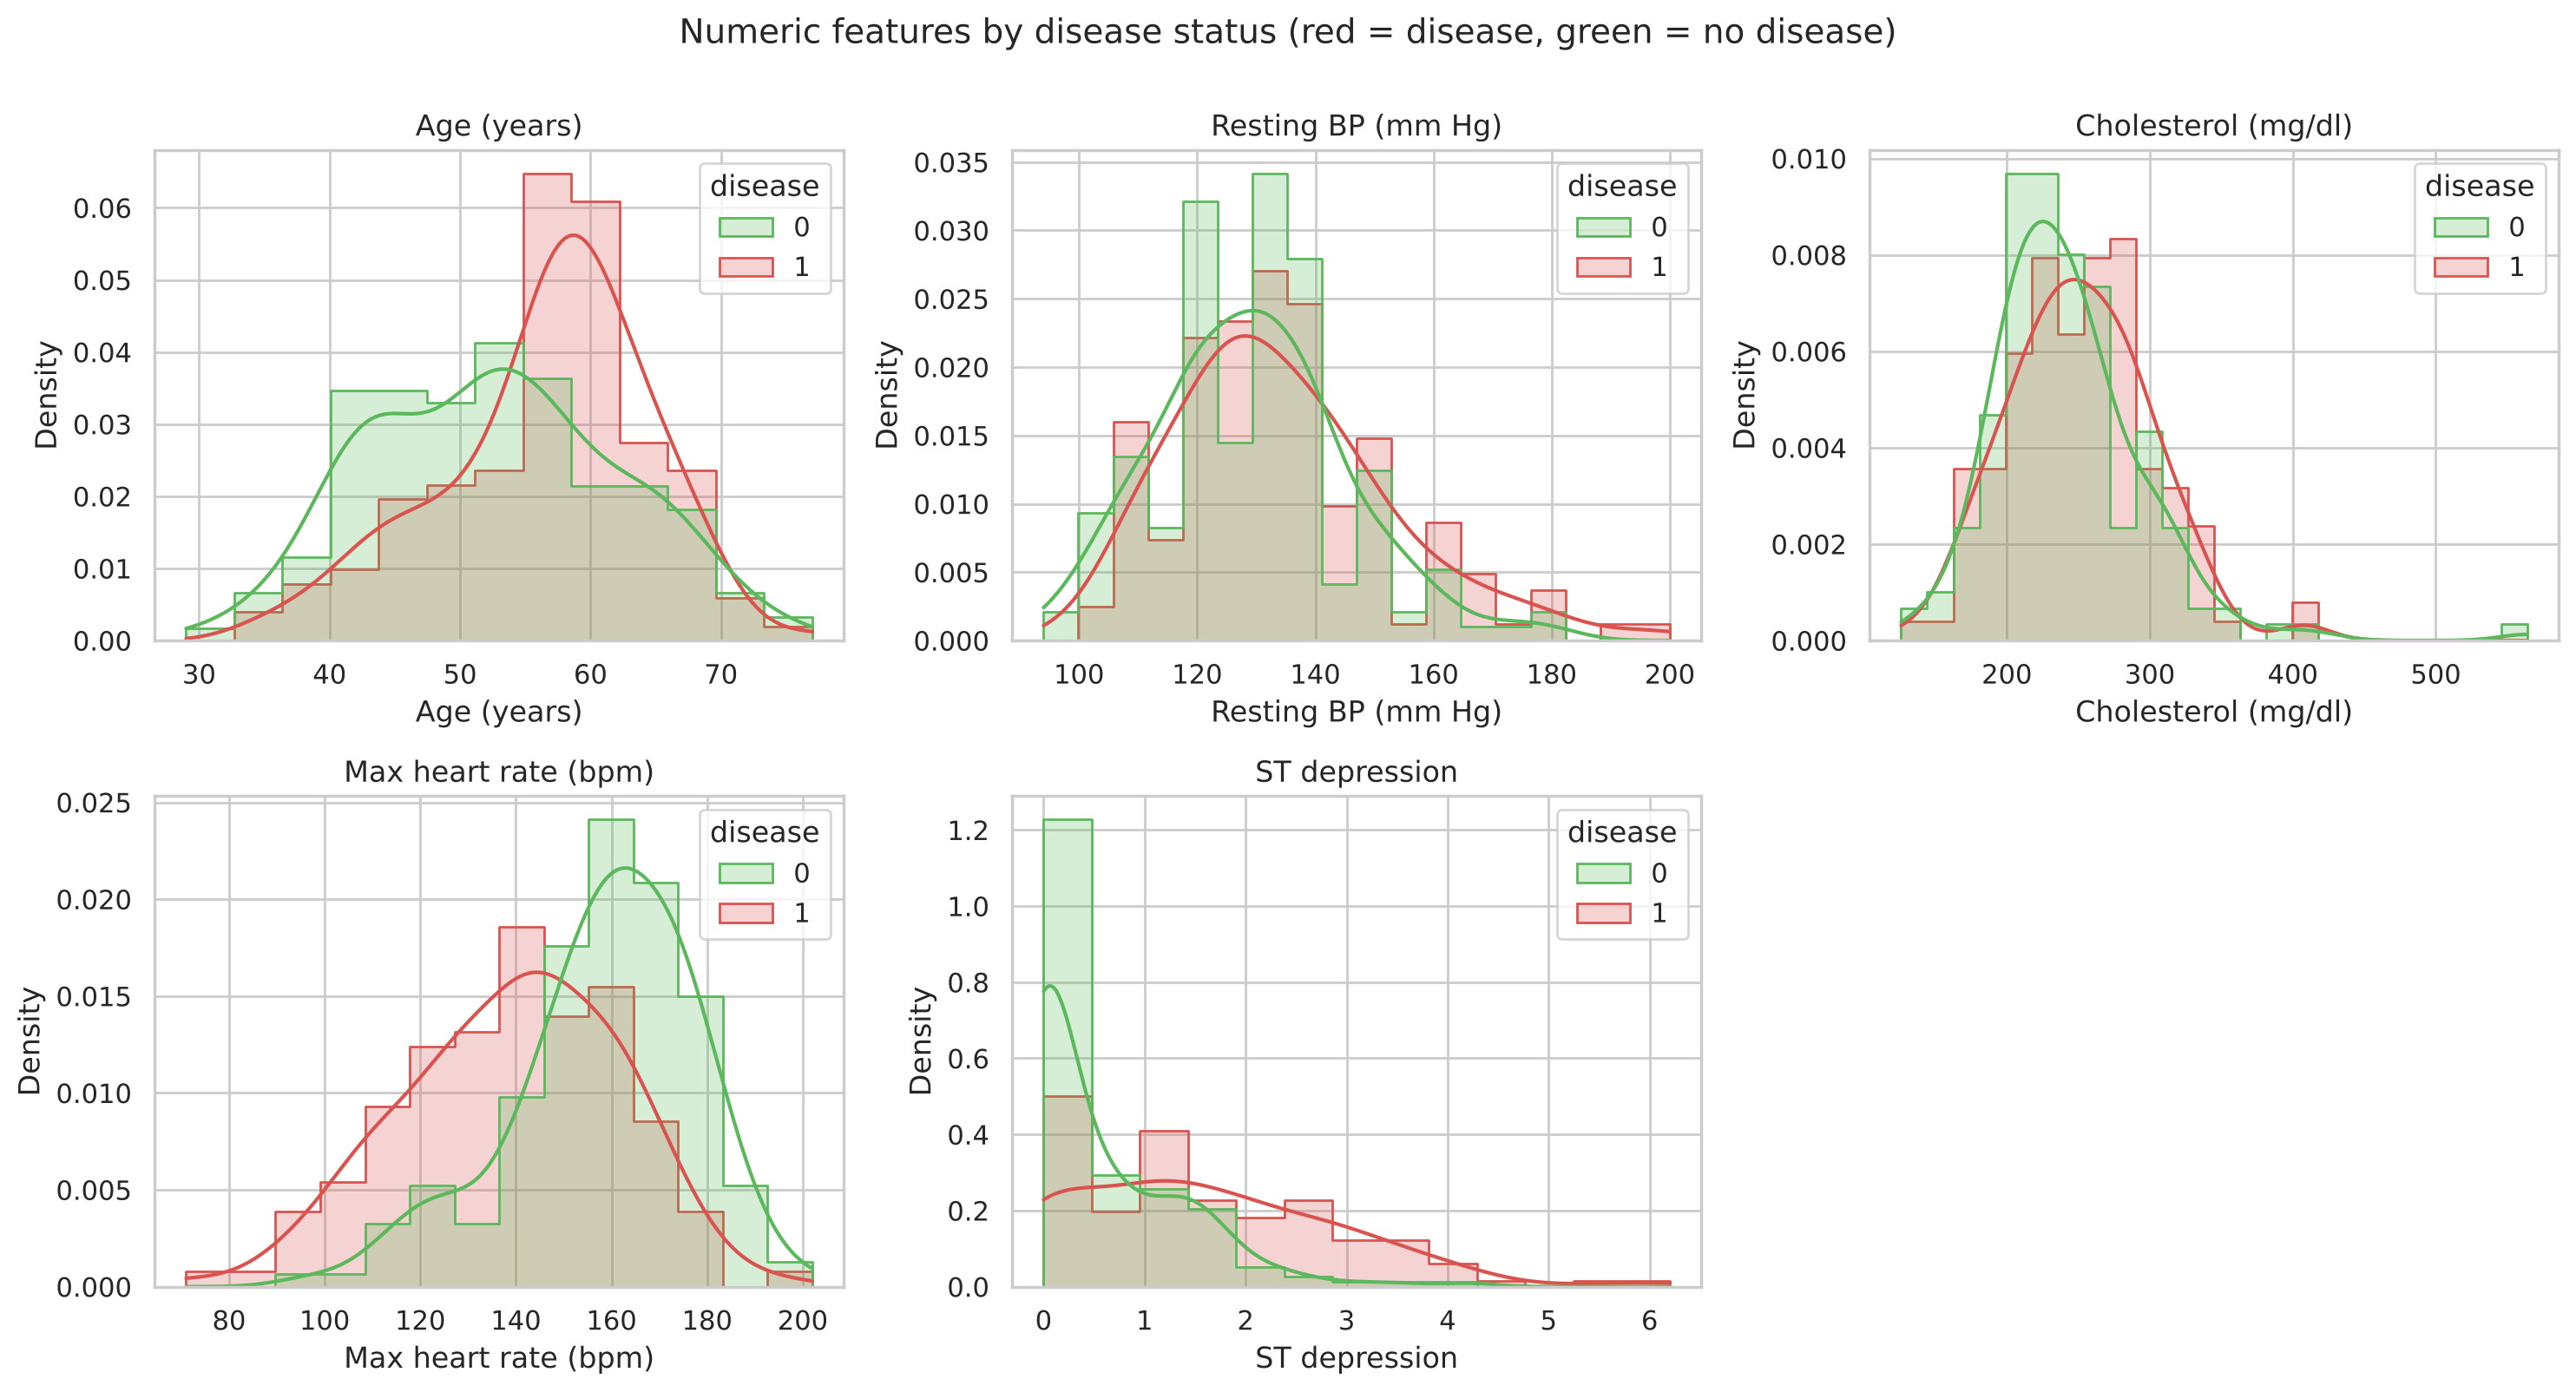

In [7]:
numeric = ["age", "trestbps", "chol", "thalach", "oldpeak"]
labels = {"age": "Age (years)", "trestbps": "Resting BP (mm Hg)", "chol": "Cholesterol (mg/dl)",
          "thalach": "Max heart rate (bpm)", "oldpeak": "ST depression"}
palette = {0: "#5CB85C", 1: "#D9534F"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), numeric):
    sns.histplot(data=df, x=col, hue="disease", palette=palette, kde=True, stat="density",
                 common_norm=False, element="step", ax=ax)
    ax.set_xlabel(labels[col])
    ax.set_title(labels[col])
axes.ravel()[-1].axis("off")
fig.suptitle("Numeric features by disease status (red = disease, green = no disease)", y=1.0, fontsize=14)
plt.tight_layout()
plt.savefig(FIG / "feature_distributions.png", dpi=150)
plt.show()

In [8]:
print(df.groupby("disease")[numeric].mean().round(2).rename(index={0: "No disease", 1: "Disease"}).to_string())

              age  trestbps    chol  thalach  oldpeak
disease                                              
No disease  52.59    129.25  242.64   158.38     0.59
Disease     56.60    134.40  251.09   139.10     1.59


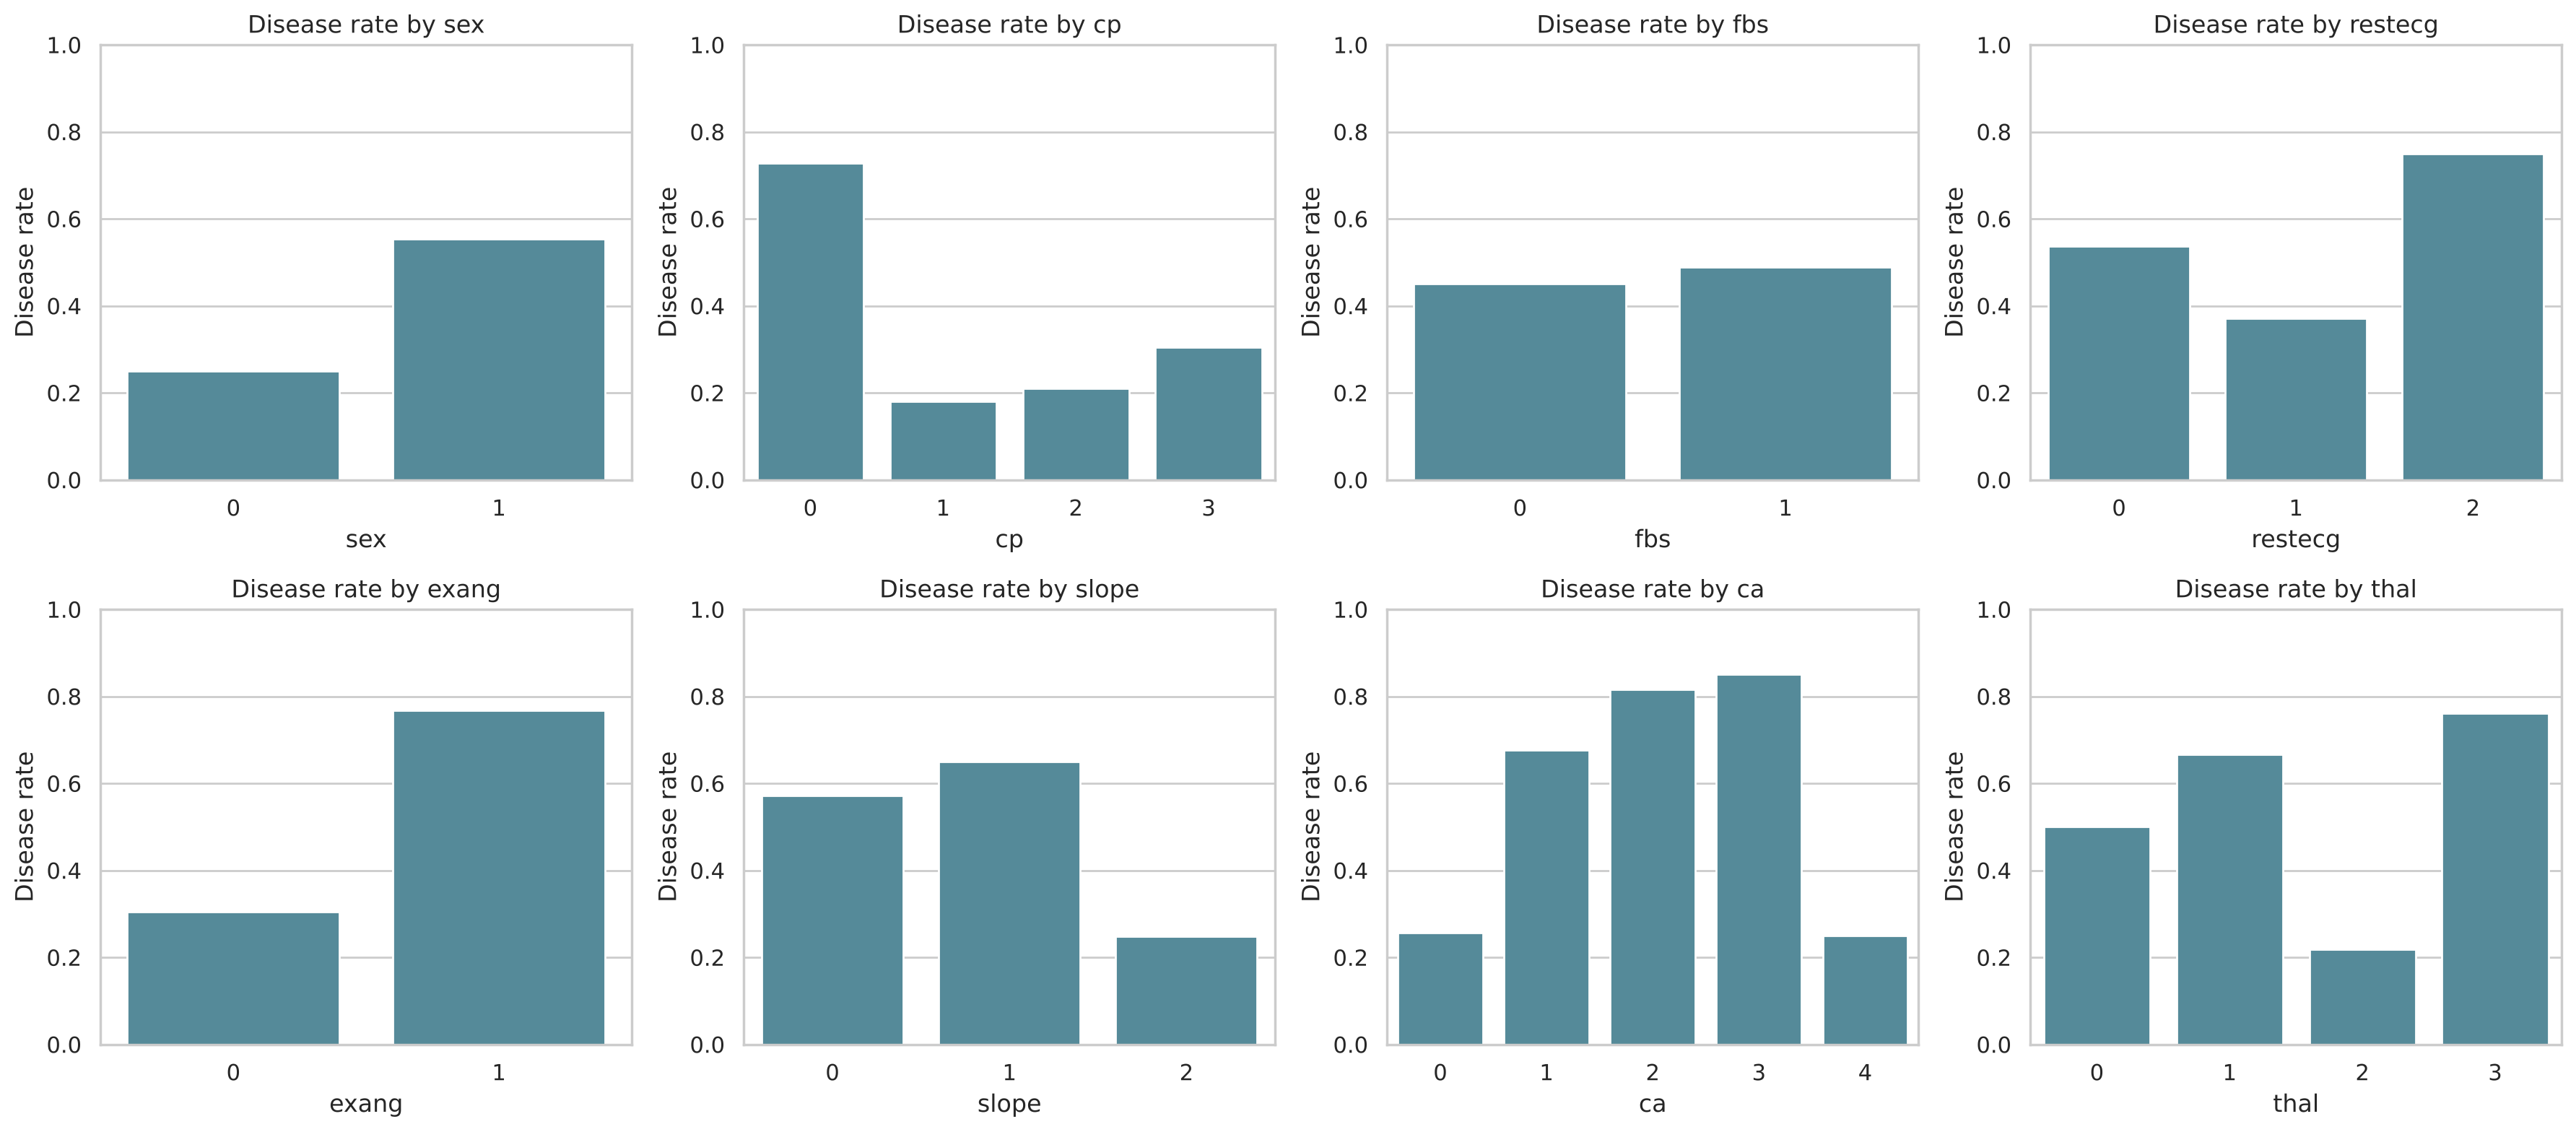

In [9]:
categorical = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), categorical):
    rate = df.groupby(col)["disease"].mean()
    sns.barplot(x=rate.index.astype(str), y=rate.values, color="#4A90A4", ax=ax)
    ax.set_ylim(0, 1)
    ax.set_xlabel(col)
    ax.set_ylabel("Disease rate")
    ax.set_title(f"Disease rate by {col}")
plt.tight_layout()
plt.savefig(FIG / "categorical_disease_rates.png", dpi=150)
plt.show()

## 4. Correlations

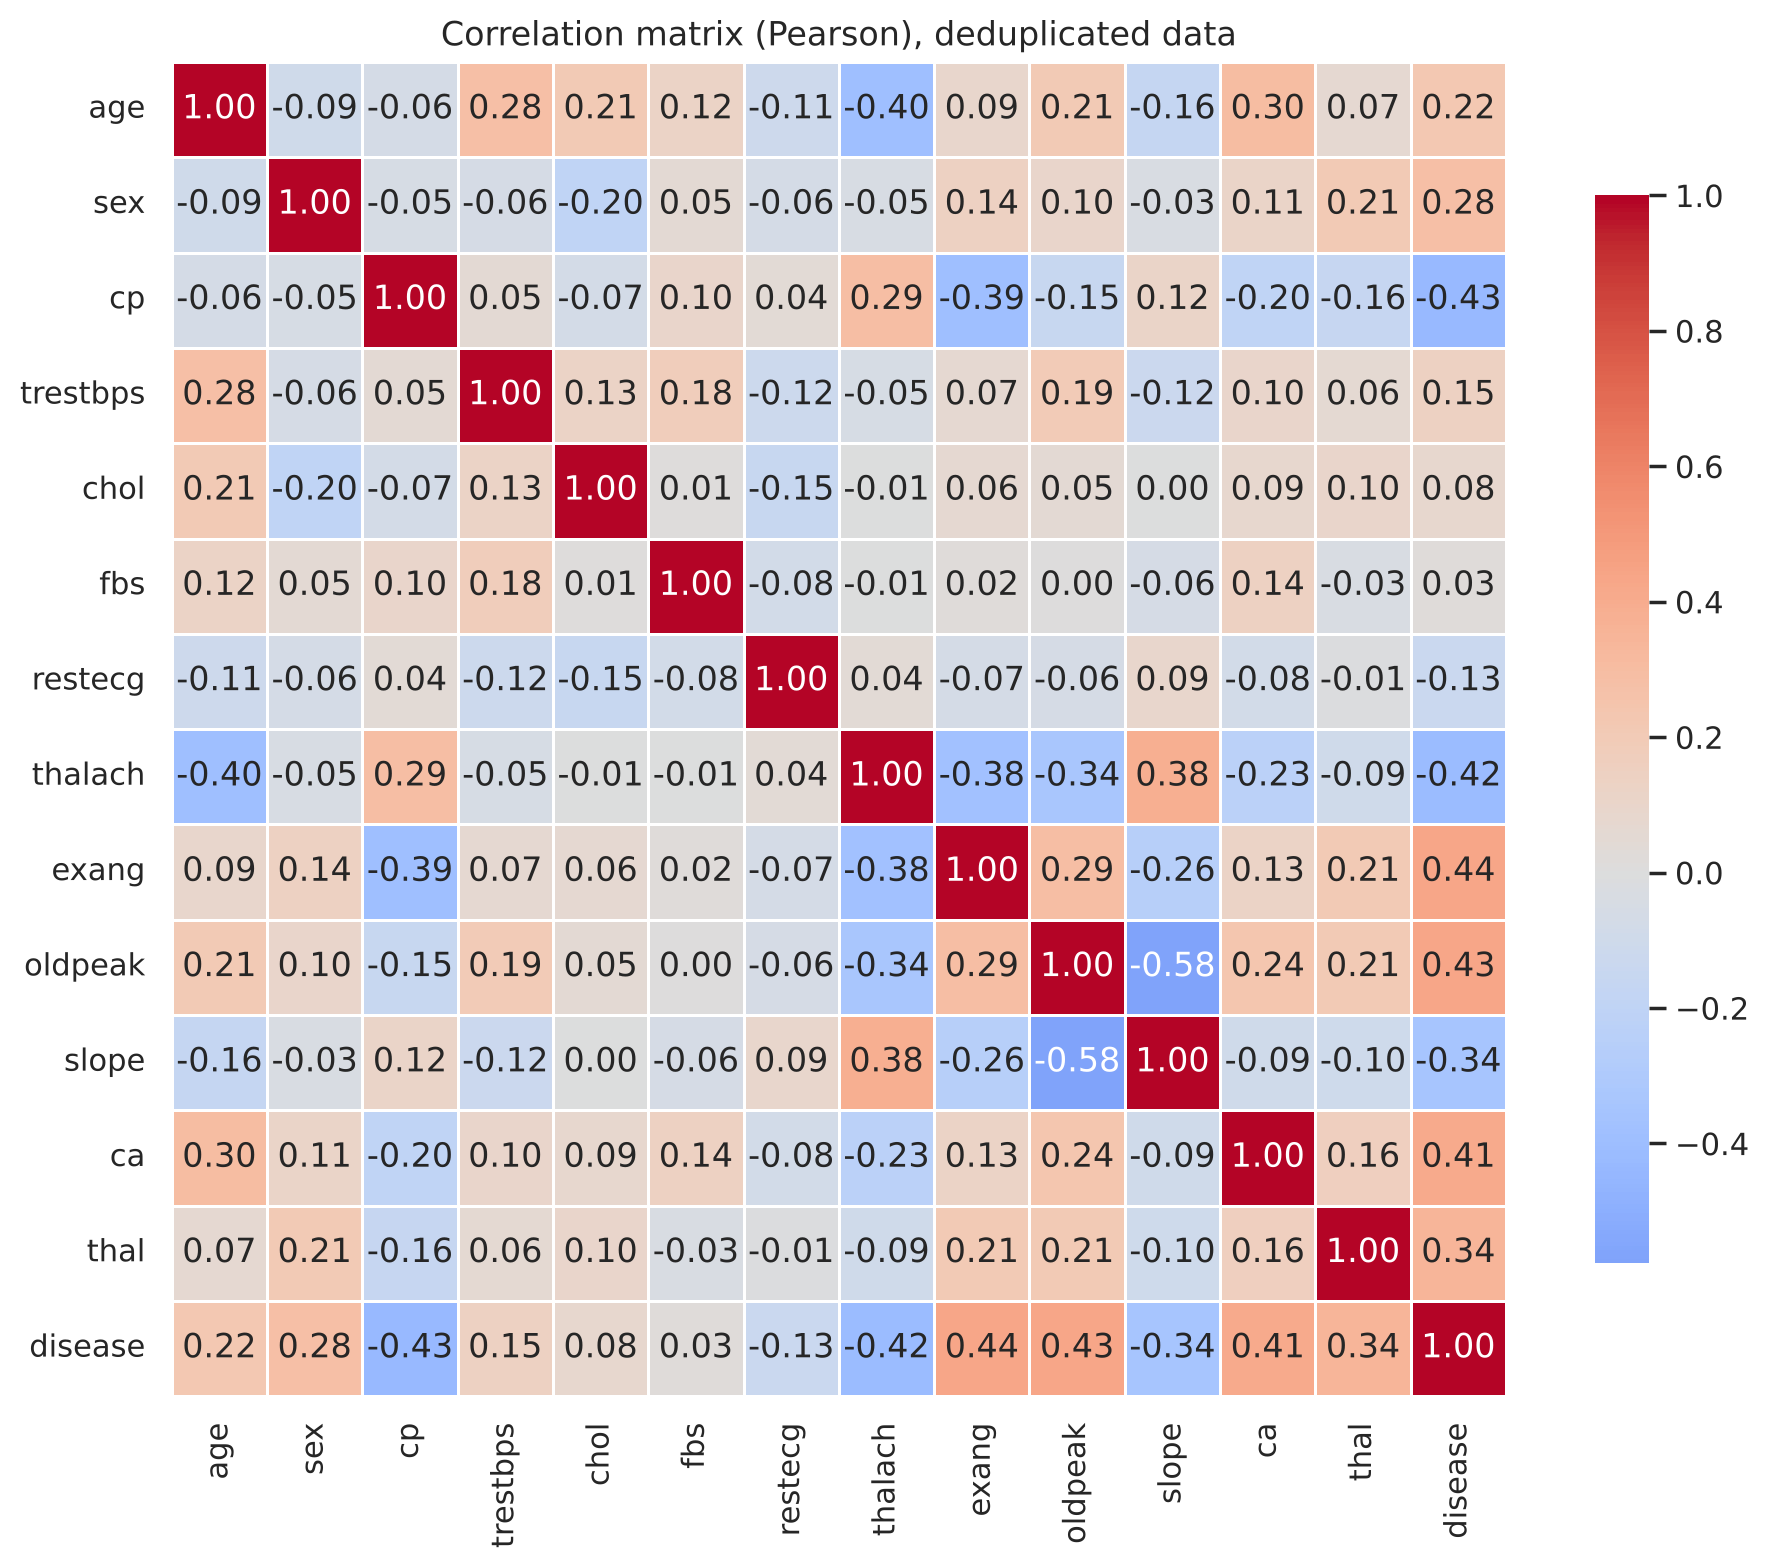

In [10]:
cols = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal", "disease"]
corr = df[cols].corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix (Pearson), deduplicated data")
plt.tight_layout()
plt.savefig(FIG / "correlation_matrix.png", dpi=150)
plt.show()

In [11]:
print("Correlation with disease (strongest first):")
print(corr["disease"].drop("disease").sort_values(key=abs, ascending=False).round(3).to_string())

Correlation with disease (strongest first):
exang       0.436
cp         -0.432
oldpeak     0.429
thalach    -0.420
ca          0.409
slope      -0.344
thal        0.343
sex         0.284
age         0.221
trestbps    0.146
restecg    -0.135
chol        0.081
fbs         0.027


## 5. Summary of EDA findings

| Question | Finding |
|---|---|
| Data quality | 1,025 raw rows contain 723 duplicates (70.5%); 302 unique patients remain. No missing values, but `ca = 4` (4 rows) and `thal = 0` (2 rows) are invalid codes. |
| Label | In the Kaggle file `target = 1` means *no* disease. The project uses `disease = 1 - target`. |
| Class balance | 138 patients with disease (45.7%) and 164 without (54.3%): fairly balanced. |
| Patients with disease | Are older on average (56.6 vs 52.6 years), have higher resting blood pressure (134 vs 129 mm Hg), a much lower maximum heart rate (139 vs 158 bpm) and more ST depression (1.59 vs 0.59). |
| Strongest correlations with disease | Exercise-induced angina (+0.44), chest pain type code (-0.43), ST depression (+0.43), maximum heart rate (-0.42) and number of major vessels (+0.41). |
| Weak signals | Cholesterol (+0.08) and fasting blood sugar (+0.03) are only weakly related to the label on their own. |

**Notes and caveats**

- `cp`, `restecg`, `slope` and `thal` are nominal codes, so the sign of their correlation has no clinical meaning; they are one-hot encoded before modelling.
- Correlation is not causation, and with only 302 unique patients these estimates carry wide uncertainty.
- The features that stand out here (heart rate, ST depression, exercise angina, vessels, thallium) are also the ones the SHAP analysis later ranks as most influential, which supports the model's behaviour.

**Next step:** `src/preprocess.py` applies the cleaning decisions above and creates the stratified train/test split.
